# 10 · Presentation figures

Simple comparisons for slides (score error and ranking), read from saved results (nothing is fitted here).
Style follows `design.md`: blue is primary, our method is the darkest blue.

| Label | What it is | Source |
|---|---|---|
| Random questions | plain accuracy on k random questions | 05 `test.csv` |
| tinyBenchmarks IRT | 1D IRT anchors + gp-IRT | 05 `test.csv` |
| Fluid adaptive (1D) | Aarya's Fluid Benchmarking | `adaptive_run_experiment.py` |
| Adaptive MIRT (ours) | V-optimal adaptive, D=3, gp-IRT | 07 `test.csv` |

All use the same 5 family splits and k; error is on held-out test models.

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from efficbench import ROOT

N_ITEMS = 14042
FIGS = ROOT / "results/figures"
FIGS.mkdir(parents=True, exist_ok=True)

STYLE = {  # label: (colour, marker), from design.md
    "Random questions": ("#9CA3AF", "s"),
    "tinyBenchmarks IRT": ("#93C5FD", "^"),
    "Fluid adaptive (1D)": ("#2563EB", "D"),
    "Adaptive MIRT (ours)": ("#1E3A8A", "o"),
}
plt.rcParams.update(
    {
        "font.size": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.alpha": 0.3,
        "legend.frameon": False,
    }
)

## Load

MAE per split and k, in percentage points (seeds averaged within a split).

In [2]:
progression = ROOT / "results/irt/progression"
info = pd.read_csv(progression / "information/test.csv")
vopt = pd.read_csv(progression / "voptimal/test.csv")
sources = [
    ("Random questions", info, "random + accuracy"),
    ("tinyBenchmarks IRT", info, "IRT anchors + gp-IRT"),
    ("Adaptive MIRT (ours)", vopt, "voptimal_adaptive + gp-IRT"),
]
fluid_path = ROOT / "results/irt/mmlu_efficbench/adaptive_test.csv"
if fluid_path.exists():
    fluid = pd.read_csv(fluid_path)
    fluid = fluid[fluid.scale == "accuracy"]
    sources.insert(2, ("Fluid adaptive (1D)", fluid, "fluid"))
else:
    print("Run scripts/irt/adaptive_run_experiment.py to add Fluid")

per_split = pd.concat(
    [
        df[df.method == method].groupby(["k", "split"]).mae.mean().mul(100).rename(label)
        for label, df, method in sources
    ],
    axis=1,
)
mean, sd = per_split.groupby("k").mean(), per_split.groupby("k").std()
mean.round(2)

,Random questions,tinyBenchmarks IRT,Fluid adaptive (1D),Adaptive MIRT (ours)
k,,,,
10,12.32,5.36,3.06,3.73
20,8.47,4.39,2.67,2.40
50,5.18,2.99,2.37,1.64
100,3.96,2.28,2.29,1.57
200,2.52,1.82,2.13,1.44
500,1.77,1.38,1.94,1.25


## 1 · Error falls as we ask more questions

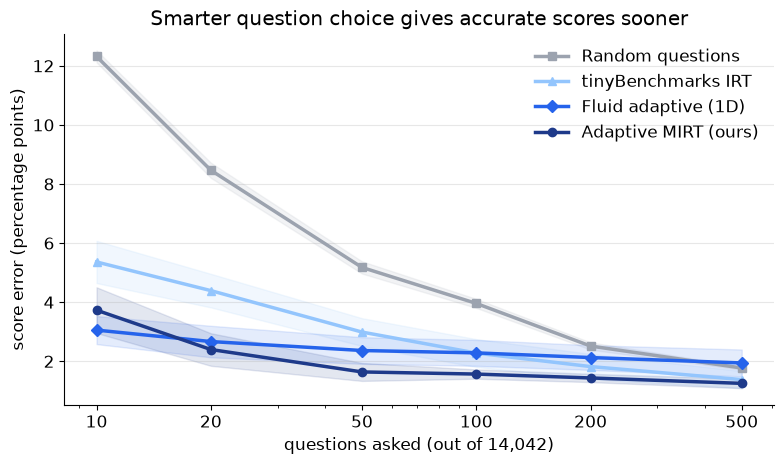

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for label in mean:
    colour, marker = STYLE[label]
    ax.plot(mean.index, mean[label], marker=marker, color=colour, lw=2.5, label=label)
    ax.fill_between(
        mean.index, mean[label] - sd[label], mean[label] + sd[label], color=colour, alpha=0.12
    )
ax.set(
    xscale="log",
    xticks=mean.index,
    xticklabels=mean.index,
    xlabel="questions asked (out of 14,042)",
    ylabel="score error (percentage points)",
    title="Smarter question choice gives accurate scores sooner",
)
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "error_vs_questions.png", dpi=200)

## 2 · Error with a fixed budget of questions

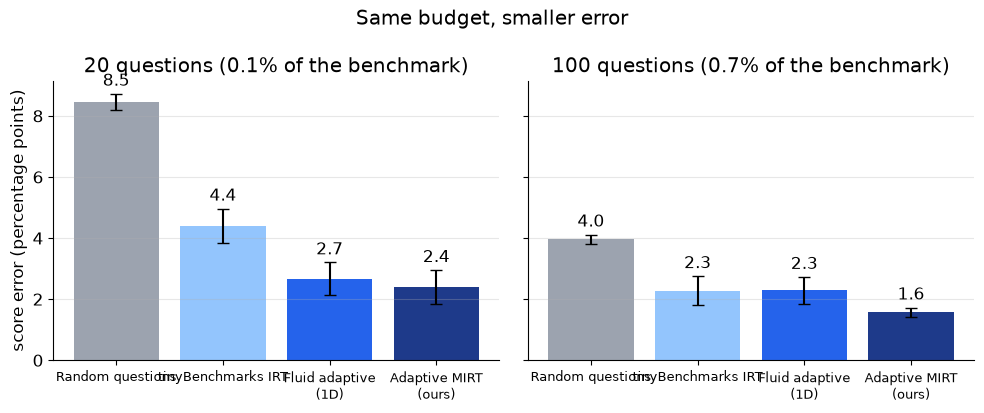

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, k in zip(axes, [20, 100], strict=True):
    colours = [STYLE[label][0] for label in mean]
    bars = ax.bar(range(len(mean.columns)), mean.loc[k], yerr=sd.loc[k], color=colours, capsize=4)
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_xticks(range(len(mean.columns)), [c.replace(" (", "\n(") for c in mean], fontsize=9)
    ax.set_title(f"{k} questions ({100 * k / N_ITEMS:.1f}% of the benchmark)")
axes[0].set_ylabel("score error (percentage points)")
fig.suptitle("Same budget, smaller error")
fig.tight_layout()
fig.savefig(FIGS / "error_at_budget.png", dpi=200)

## 3 · Questions needed for a 3-point error

Interpolated on the log-k curve above; "> 500" means the method never reached it in our budgets.

Random questions        159.0
tinyBenchmarks IRT       50.0
Fluid adaptive (1D)      11.0
Adaptive MIRT (ours)     15.0
dtype: float64

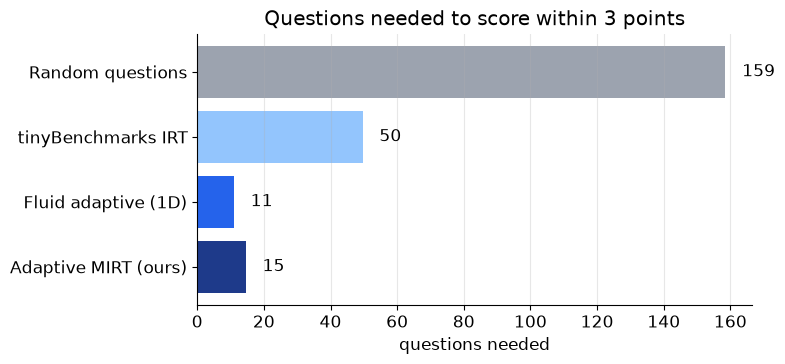

In [5]:
TARGET = 3.0


def questions_needed(curve):
    below = curve.values <= TARGET
    if not below.any():
        return np.nan
    i = below.argmax()
    if i == 0:
        return curve.index[0]
    x0, x1 = np.log(curve.index[i - 1]), np.log(curve.index[i])
    y0, y1 = curve.values[i - 1], curve.values[i]
    return float(np.exp(x0 + (TARGET - y0) * (x1 - x0) / (y1 - y0)))


needed = mean.apply(questions_needed)
fig, ax = plt.subplots(figsize=(8, 3.8))
y = range(len(needed))
ax.barh(y, needed.fillna(500), color=[STYLE[label][0] for label in needed.index])
for i, n in enumerate(needed):
    ax.text((n if n == n else 500) + 5, i, "> 500" if n != n else f"{n:.0f}", va="center")
ax.set_yticks(y, needed.index)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)
ax.set(xlabel="questions needed", title=f"Questions needed to score within {TARGET:.0f} points")
fig.tight_layout()
fig.savefig(FIGS / "questions_needed.png", dpi=200)
needed.round(0)

## 4 · Do we put models in the right order?

Spearman's ρ compares the leaderboard order we predict with the true full-benchmark order:
1 means the same order, 0 means no relation. This matters when the question is "which
model is better?" rather than "what is its exact score?". Mean ±1 SD across splits.

,Random questions,tinyBenchmarks IRT,Fluid adaptive (1D),Adaptive MIRT (ours)
k,,,,
10,0.660,0.797,0.941,0.899
20,0.733,0.864,0.948,0.922
50,0.875,0.925,0.957,0.959
100,0.916,0.951,0.961,0.972
200,0.944,0.963,0.965,0.976
500,0.973,0.977,0.973,0.980


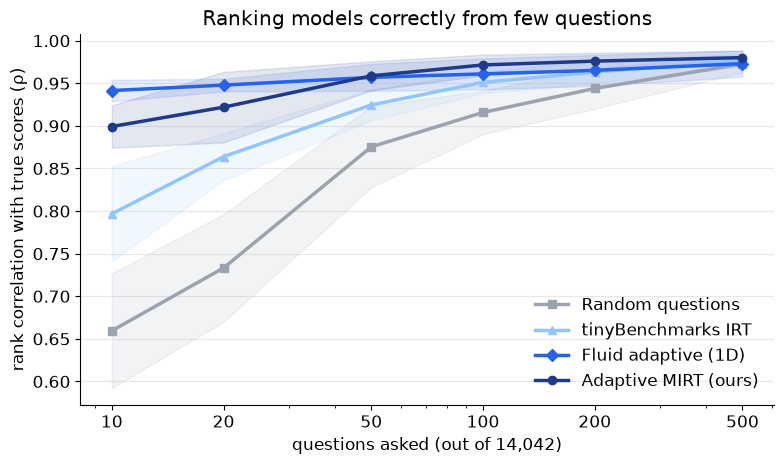

In [6]:
rho = pd.concat(
    [
        df[df.method == method].groupby(["k", "split"]).spearman.mean().rename(label)
        for label, df, method in sources
    ],
    axis=1,
).groupby("k")
rho_mean, rho_sd = rho.mean(), rho.std()

fig, ax = plt.subplots(figsize=(8, 4.8))
for label in rho_mean:
    colour, marker = STYLE[label]
    m, s = rho_mean[label], rho_sd[label]
    ax.plot(m.index, m, marker=marker, color=colour, lw=2.5, label=label)
    ax.fill_between(m.index, m - s, m + s, color=colour, alpha=0.12)
ax.set(
    xscale="log",
    xticks=rho_mean.index,
    xticklabels=rho_mean.index,
    xlabel="questions asked (out of 14,042)",
    ylabel="rank correlation with true scores (ρ)",
    title="Ranking models correctly from few questions",
)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGS / "spearman_vs_questions.png", dpi=200)
rho_mean.round(3)

## 5 · What a rank correlation looks like

Each dot is one held-out model (split 0, 20 questions). For methods with random seeds we
show the seed with the median ρ, so each panel is typical rather than lucky or unlucky. Its true rank is on the
x-axis and its predicted rank on the y-axis. Dots on the diagonal are ranked correctly;
the tighter the cloud, the higher ρ.

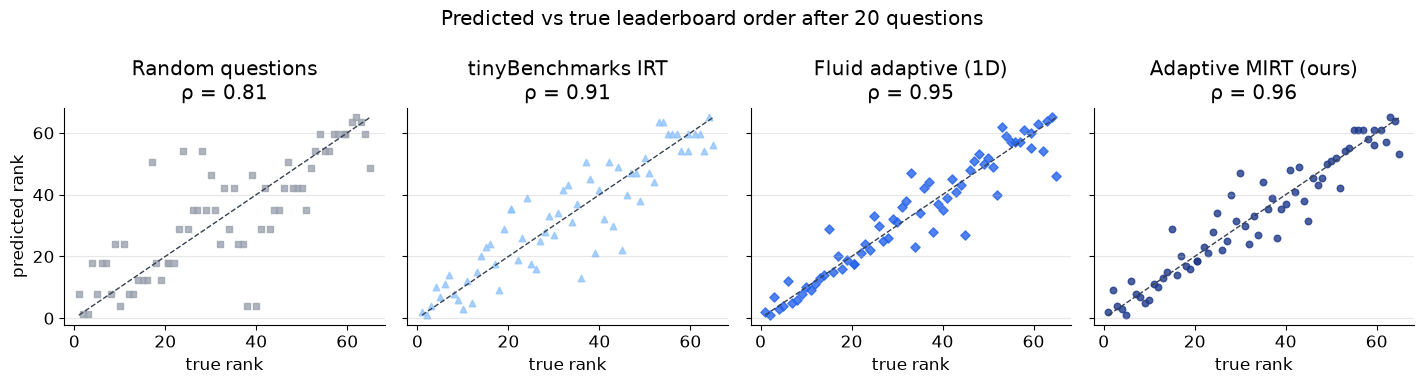

In [7]:
K_RANK = 20
info_pred = pd.read_csv(progression / "information/predictions.csv")
vopt_pred = pd.read_csv(progression / "voptimal/predictions.csv")
per_model = {
    "Random questions": info_pred[info_pred.method == "random + accuracy"],
    "tinyBenchmarks IRT": info_pred[info_pred.method == "IRT anchors + gp-IRT"],
    "Adaptive MIRT (ours)": vopt_pred[vopt_pred.method == "voptimal_adaptive + gp-IRT"],
}
if fluid_path.exists():
    thetas = pd.read_csv(fluid_path.with_name("adaptive_thetas.csv"))
    per_model["Fluid adaptive (1D)"] = thetas[thetas.method == "fluid"].rename(
        columns={"true_accuracy": "true_score", "expected_accuracy": "pred_score"}
    )

labels = [label for label in STYLE if label in per_model]
fig, axes = plt.subplots(1, len(labels), figsize=(3.6 * len(labels), 3.9), sharey=True)
for ax, label in zip(axes, labels, strict=True):
    d = per_model[label]
    d = d[(d.split == 0) & (d.k == K_RANK)].fillna({"seed": 0})  # Fluid has no seed
    by_seed = (
        d.groupby("seed")[["true_score", "pred_score"]].corr("spearman").xs("true_score", level=1)
    )
    median_seed = (by_seed.pred_score - by_seed.pred_score.median()).abs().idxmin()
    d = d[d.seed == median_seed]
    true, pred = d.true_score.rank(), d.pred_score.rank()
    colour, marker = STYLE[label]
    ax.scatter(true, pred, color=colour, marker=marker, s=22, alpha=0.8)
    ax.plot([1, len(d)], [1, len(d)], color="#374151", lw=1, ls="--")
    ax.set(title=f"{label}\nρ = {true.corr(pred):.2f}", xlabel="true rank")
axes[0].set_ylabel("predicted rank")
fig.suptitle(f"Predicted vs true leaderboard order after {K_RANK} questions")
fig.tight_layout()
fig.savefig(FIGS / "rank_scatter.png", dpi=200)